# Ariketa 4.2 — Erregresio anizkoitza + metrikak 📊 (EGITEKO)

1. saioan:

```text
weight
  ↓
Linear Regression
  ↓
mpg
```

Orain bi galdera berri:

```text
1. Zer gertatzen da feature gehiago erabiltzen baditugu?
Ona: Informazio baliagarria bada, ereduaren zehaztasuna hobetzen da ($R^2$ altuagoa).Txarra: Zarata edo aldagai alferrikakoak sartuz gero, overfitting-a (gainegokitzea) gertatzen da eta test-multzoan emaitza txarragoak ematen ditu.
2. Nola neurtzen dugu zenbakizko iragarpen baten kalitatea?
MAE: Batez besteko akats absolutua (jatorrizko unitateetan, interpretatzeko errazena).MSE: Errore karratua (akats handiei zigor handiagoa ematen die).RMSE: MSEren erro karratua (akats handiak zigortzen ditu, baina jatorrizko unitateetan).$R^2$: Ereduak azaltzen duen datuen aldakortasun ehunekoa ($0$-tik $1$-era; $1$ = %100 azalduta).
```

Landuko dugu:

```text
Erregresio anizkoitza
        ↓
koefizienteak
        ↓
MAE / MSE / RMSE / R²
        ↓
benetakoa vs iragarria
        ↓
MSE → hurrengo saioan Gradient Descent
```

### Nola lan egin

- 🟢 **KOMENTATU:** azaldu zure hitzekin.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU ZEROTIK:** kode-zati labur bat idatzi.


# 2.0 — Prestaketa 🔎

Target-a:

```text
mpg = miles per gallon
```

Beraz `mpg` **erregai-eraginkortasuna** da:

```text
mpg handiagoa → gallon bakoitzarekin kilometro/milia gehiago
```

Sei feature numeriko erabiliko ditugu:

```text
weight
horsepower
displacement
cylinders
acceleration
model_year
```

⚠️ Lehenengo ariketan bezala, **erabiliko ditugun zutabeak aukeratu eta gero** tratatuko ditugu null-ak.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split

df_raw = sns.load_dataset("mpg")

ezaugarriak = [
    "weight",
    "horsepower",
    "displacement",
    "cylinders",
    "acceleration",
    "model_year",
]


# ============================================================
# 🟡 HUTSUNEAK BETE
# ============================================================
#
# Hautatu feature-ak + target-a, ETA GERO kendu null-ak.

df = df_raw[ezaugarriak + ["mpg"]].copy()

print("Null-ak dropna() aurretik:")

print(df.isnull().sum())

df = df.dropna()


X = df[ezaugarriak]

y = df["mpg"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)


print("\nAldagaiak:", len(ezaugarriak))

print("TRAIN:", X_train.shape)

print("TEST:", X_test.shape)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Zergatik ez dugu df_raw.dropna() zuzenean egiten?
#
# ERANTZUNA:
# Lehenik erabili behar ditugun aldagaiak bakarrik hautatzen ditugunez (ezaugarriak + mpg),
# dropna()-k ereduarentzat benetan beharrezkoak diren zutabeetan nuluak diren errenkadak
# bakarrik ezabatuko ditu. Hasieratik df_raw.dropna() egingo bagenu, erabili behar ez ditugun
# beste zutabe batzuetan balio nuluak zituzten errenkadak ere ezabatuko lirateke, alferrik
# datu baliagarriak galduz.

Null-ak dropna() aurretik:
weight          0
horsepower      6
displacement    0
cylinders       0
acceleration    0
model_year      0
mpg             0
dtype: int64

Aldagaiak: 6
TRAIN: (313, 6)
TEST: (79, 6)


# 2.1 — Konparazio bidezkoa: feature 1 vs 6 🧪

Ez dugu 1. saioko R² zenbakia *hard-code* egingo.

Zergatik?

> Split desberdin batekin edo errenkada multzo desberdin batekin konparatzea ez litzateke guztiz bidezkoa izango.

Beraz, **oraingo TRAIN/TEST bera erabiliz** bi modelo entrenatuko ditugu:

```text
A) weight bakarrik
B) 6 feature
```

Horrela feature gehiago gehitzeak esperimentu honetan zer eragin duen ikusiko dugu.


In [2]:
# ============================================================
# A) WEIGHT BAKARRIK
# ============================================================

eredua_weight = LinearRegression()

eredua_weight.fit(
    X_train[[
        "weight"
    ]],
    y_train
)

r2_weight = r2_score(
    y_test,
    eredua_weight.predict(
        X_test[[
            "weight"
        ]]
    )
)


# ============================================================
# B) 6 FEATURE
# ============================================================

eredua = LinearRegression()

eredua.fit(
    X_train,
    y_train
)

iragarpenak = eredua.predict(
    X_test
)

r2_anizkoitza = r2_score(
    y_test,
    iragarpenak
)


print(
    "R² weight bakarrik:",
    round(r2_weight, 3)
)

print(
    "R² 6 feature:",
    round(r2_anizkoitza, 3)
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Esperimentu honetan feature gehiago gehitzeak TEST R² hobetu al du?
#
# ERANTZUNA:
# Bai, hobetu du. Ezaugarri berriek (`model_year`, `horsepower`, etab.) informazio
# baliagarria ematen diote ereduari autoaren kontsumoa (`mpg`) zehatzago adierazteko.
#
#
# Horrek esan nahi al du "feature gehiago = beti hobe"?
#
# ERANTZUNA:
# Ez. Zarata edo garrantzirik gabeko feature-ak gehitzeak overfitting-a eragin dezake
# (TRAIN-en hobetu baina TEST-en okertu), eta oso korrelazionatutako feature-ek
# (multikolinealtasuna) koefizienteak ezegonkor bihurtzen dituzte. Beti egiaztatu behar
# da esperimentalki, TEST multzoarekin.

R² weight bakarrik: 0.653
R² 6 feature: 0.794


# 2.2 — Erregresio anizkoitza: hiperplano bat 🧠

Feature bakarrarekin:

$$
\hat{y} = wx+b
$$

Sei feature-rekin:

$$
\hat{y}
=
w_1x_1+w_2x_2+\dots+w_6x_6+b
$$

Koefiziente bakoitzaren interpretazioa:

> **feature hori unitate 1 aldatzean, beste feature-ak berdin mantenduta, aurreikusitako mpg-a zenbat aldatzen den.**

Baina bi kontu:

1. Feature-ek **unitate desberdinak** dituzte (`lb`, horsepower, cylinders...).  
   → koefizienteen tamaina absolutuak ezin dira zuzenean alderatu “importance” gisa.

2. Feature batzuk elkarren artean erlazionatuta egon daitezke.  
   → koefizientea **ez da kausalitatea**.


Ez dugu scaling egingo hemen: `LinearRegression`-ek ez du behar iragarpen zuzenak egiteko, eta jatorrizko unitateak mantentzeak koefizienteen interpretazioa errazten du.


In [3]:
koefizienteak = pd.DataFrame({
    "feature": ezaugarriak,
    "coefficient": eredua.coef_
})

display(
    koefizienteak.round(4)
)

print(
    "Intercept b:",
    round(
        eredua.intercept_,
        3
    )
)


,feature,coefficient
0,weight,-0.0066
1,horsepower,-0.0023
2,displacement,0.0010
3,cylinders,-0.1162
4,acceleration,0.0617
5,model_year,0.7606


Intercept b: -15.058


## 2.3 — 🟢 Koefizienteak unitate errealetan interpretatu

Koefiziente txiki batek ez du derrigorrez feature “gutxi garrantzitsua” esan nahi.

Adibidez, `weight` lb-tan dago. Horregatik erabilgarriagoa da galdetzea:

> **100 lb gehiago → zenbat mpg-ko aldaketa aurreikusten du modeloak?**

Eta `horsepower`-entzat:

> **10 hp gehiago → zenbat mpg-ko aldaketa?**

### Osatu

```text
weight +100 lb
→ coefficient_weight × 100 = -0.0066 × 100
→ ≈ -0.66 mpg aldaketa

horsepower +10 hp
→ coefficient_hp × 10 = -0.0023 × 10
→ ≈ -0.02 mpg aldaketa
```

### 🟢 Galdera

Zergatik ez dugu `abs(coefficient)` handiena duen feature-a automatikoki “garrantzitsuena” dela esaten?

**ERANTZUNA:**
Koefizientearen tamaina aldagai bakoitzaren eskalaren edo unitateen mende dagoelako, eta ez soilik bere benetako garrantziaren mende:Eskalaren eragina: weight milatan neurtzen da (librak), beraz bere pisua ($w$) oso txikia izango da, nahiz eta eragin handia izan. Aldiz, model_year-ek zenbaki txikiak erabiltzen ditu, beraz bere $w$ askoz handiagoa agertuko da.Multikolinearitatea: Hainbat aldagaik informazio bera ematen badute (adibidez, zilindrada eta potentzia), ereduak koefizienteak beren artean banatu edo desitxuratu egiten ditu.


In [4]:
w_weight = eredua.coef_[
    ezaugarriak.index(
        "weight"
    )
]

w_hp = eredua.coef_[
    ezaugarriak.index(
        "horsepower"
    )
]


print(
    "weight +100 lb →",
    round(
        w_weight * 100,
        2
    ),
    "mpg"
)

print(
    "horsepower +10 hp →",
    round(
        w_hp * 10,
        2
    ),
    "mpg"
)


weight +100 lb → -0.66 mpg
horsepower +10 hp → -0.02 mpg


# 2.4 — Erregresio-metrikak: MAE, MSE, RMSE eta R² 📏

Sailkapenean `accuracy` erabil genezake.

Erregresioan, irteera zenbakia denez, galdetzen dugu:

> **Zenbat urrundu gara benetako baliotik?**

### MAE

$$
MAE
=
\frac{1}{n}
\sum_{i=1}^{n}
|y_i-\hat{y}_i|
$$

- unitate errealetan dago (`mpg`)
- oso zuzena interpretatzeko

### MSE

$$
MSE
=
\frac{1}{n}
\sum_{i=1}^{n}
(y_i-\hat{y}_i)^2
$$

- errore handiak gogorrago zigortzen ditu
- unitatea `mpg²`
- **hurrengo saioan loss gisa minimizatuko dugu Gradient Descent-ekin**

### RMSE

$$
RMSE = \sqrt{MSE}
$$

- errore handiek pisu handiagoa dute
- berriro `mpg` unitateetan dago

### R²

$$
R^2
=
1-
\frac{\sum (y_i-\hat{y}_i)^2}
{\sum (y_i-\bar y)^2}
$$

Intuizioa:

```text
R² = 1 → perfektua
R² = 0 → test-eko batezbesteko-baselinearen maila
R² < 0 → baseline hori baino okerragoa
```


In [5]:
# ============================================================
# 🟡 HUTSUNEAK BETE
# ============================================================

mae = mean_absolute_error(
    y_test,
    iragarpenak
)

mse = mean_squared_error(
    y_test,
    iragarpenak
)

rmse = np.sqrt(
    mse
)

r2 = r2_score(
    y_test,
    iragarpenak
)


print(
    "MAE :",
    round(mae, 2),
    "mpg"
)

print(
    "MSE :",
    round(mse, 2),
    "mpg²"
)

print(
    "RMSE:",
    round(rmse, 2),
    "mpg"
)

print(
    "R²  :",
    round(r2, 3)
)

MAE : 2.5 mpg
MSE : 10.5 mpg²
RMSE: 3.24 mpg
R²  : 0.794


# 2.5 — Ikusi iragarpenak: benetakoa vs iragarria 👀

Grafiko honetan:

```text
x → benetako mpg
y → modeloko mpg iragarpena
```

Marra diagonala:

```text
y = x
```

izango litzateke **iragarpen perfektua**.

Puntu bat diagonaletik zenbat eta urrunago egon, orduan eta handiagoa da bere errorea.


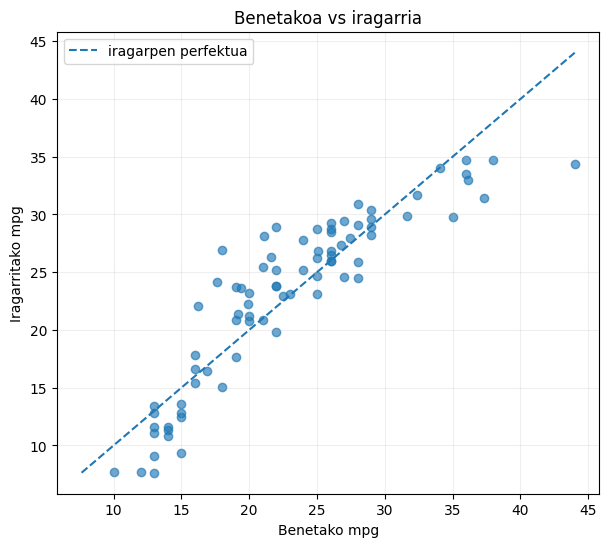

In [6]:
plt.figure(
    figsize=(7, 6)
)

plt.scatter(
    y_test,
    iragarpenak,
    alpha=0.65
)

m = min(
    y_test.min(),
    iragarpenak.min()
)

M = max(
    y_test.max(),
    iragarpenak.max()
)

plt.plot(
    [m, M],
    [m, M],
    linestyle="--",
    label="iragarpen perfektua"
)

plt.xlabel(
    "Benetako mpg"
)

plt.ylabel(
    "Iragarritako mpg"
)

plt.title(
    "Benetakoa vs iragarria"
)

plt.legend()
plt.grid(
    alpha=0.2
)

plt.show()


# 2.6 — 🟢 Metrikak interpretatu

Osatu:

### MAE

> Batez beste, gure iragarpena benetako baliotik gutxi gorabehera **2.5 mpg** urruntzen da.

### RMSE

`RMSE` normalean `MAE` baino handiagoa edo berdina izango da, erroreak karratura igotzen direlako.

> **RMSE > MAE izatea bakarrik ez da froga errore handiak daudela; diferentziaren tamainak eman dezake pista.**

### R²

> TEST multzo honetan, modeloak batezbesteko-baselinearekin alderatuta errore karratua nabarmen murrizten du.

### 🟢 Galdera

Zergatik dago RMSE `mpg`-tan baina MSE `mpg²`-tan?

**ERANTZUNA:**
MSE-n (Mean Squared Error), iragarpen-akatsak ($y - \hat{y}$) karratura jasotzen dira. Ondorioz, unitateak ere karratura igotzen dira: $(\text{mpg})^2 = \text{mpg}^2$.RMSE-n (Root Mean Squared Error), aldiz, MSEren erro karratua ($\sqrt{\text{MSE}}$) kalkulatzen da. Erro karratuak karratua bertan behera uzten du: $\sqrt{\text{mpg}^2} = \text{mpg}$.


# 2.7 — Zein kasutan huts egiten du gehiago? 🔍

MAE eta RMSE zenbaki bakarrak dira.

Orain banakako erroreak ikusiko ditugu:

```text
residual = benetakoa - iragarria
absolute_error = |residual|
```

Eta TEST multzoko 5 errore handienak erakutsiko ditugu.


In [7]:
diagnostikoa = pd.DataFrame({
    "benetako_mpg": y_test.values,
    "iragarritako_mpg": iragarpenak
})

diagnostikoa[
    "residual"
] = (
    diagnostikoa["benetako_mpg"]
    - diagnostikoa["iragarritako_mpg"]
)

diagnostikoa[
    "errore_absolutua"
] = diagnostikoa[
    "residual"
].abs()


display(
    diagnostikoa.sort_values(
        "errore_absolutua",
        ascending=False
    ).head(5).round(2)
)


,benetako_mpg,iragarritako_mpg,residual,errore_absolutua
21,44.0,34.37,9.63,9.63
73,18.0,26.88,-8.88,8.88
64,21.1,28.14,-7.04,7.04
54,22.0,28.90,-6.90,6.90
74,17.6,24.18,-6.58,6.58


# 2.8 — 🔴 MAE eta RMSE eskuz

Orain sklearn gabe.

Erabili:

```text
errorea = y - ŷ

MAE
→ abs(error)
→ mean

RMSE
→ error²
→ mean
→ sqrt
```

Helburua:

> **metrikak formula arruntak direla ikustea.**


In [8]:
# 🔴 KODETU ZEROTIK
#
# Kalkulatu:
#
# 1. errorea
# 2. mae_eskuz
# 3. rmse_eskuz
# 4. konparatu sklearn-eko mae / rmse balioekin


# IDATZI HEMEN:
# 1. errorea
errorea = y_test - iragarpenak

# 2. mae_eskuz
mae_eskuz = np.mean(np.abs(errorea))

# 3. rmse_eskuz
rmse_eskuz = np.sqrt(np.mean(errorea**2))

# 4. konparatu sklearn-eko mae / rmse balioekin
print("MAE (eskuz):  ", round(mae_eskuz, 2), "mpg")
print("MAE (sklearn):", round(mae, 2), "mpg")
print("Berdinak dira?:", np.isclose(mae_eskuz, mae))

print("\nRMSE (eskuz):  ", round(rmse_eskuz, 2), "mpg")
print("RMSE (sklearn):", round(rmse, 2), "mpg")
print("Berdinak dira?:", np.isclose(rmse_eskuz, rmse))


MAE (eskuz):   2.5 mpg
MAE (sklearn): 2.5 mpg
Berdinak dira?: True

RMSE (eskuz):   3.24 mpg
RMSE (sklearn): 3.24 mpg
Berdinak dira?: True


# 2.9 — 🟢 Hurrengo pausorako zubia: MSE → Gradient Descent

Orain badakigu:

```text
modeloa
→ iragarpenak
→ erroreak
→ MSE
```

Hurrengo galdera:

> **Nola aldatzen ditugu w₁, w₂, ..., w₆ eta b MSE txikiagoa izan dadin?**

Hurrengo saioan:

```text
uneko w eta b
    ↓
predict
    ↓
MSE
    ↓
gradient
    ↓
w eta b eguneratu
    ↓
repeat
```

### 🟢 Galdera

Zein da Deep Learning-ekin lotura?

**ERANTZUNA:**
Neurona bat = Erregresio Lineala: Neurona bakoitzaren barne-kalkulua hitzez hitz $z = w \cdot x + b$ da.Errore bera (MSE): Erregresioko sare neuronalek MSE bera erabiltzen dute galera-funtzio (Loss Function) gisa.Deep Learning-erako jauzia: Horrelako neurona asko geruzatan lotzean eta aktibazio ez-linealak (ReLU, Sigmoidea) gehitzean datza, erlazio konplexuak ikasi ahal izateko.


# Ondorioak ✅

1. **Erregresio anizkoitza**: feature batetik feature askotara pasatzen gara.
2. Feature gehiago erabiltzeak **ez du automatikoki** modelo hobea bermatzen; esperimentuan egiaztatu behar da.
3. Koefiziente bakoitza feature baten aldaketarekin lotzen da, **besteak berdin mantenduta**.
4. Koefizienteen tamainak ezin dira zuzenean importance gisa alderatu feature-ek unitate desberdinak badituzte.
5. **MAE** → errore absolutu tipikoa, unitate errealetan.
6. **MSE** → errore karratuak; hurrengo saioan loss gisa erabiliko dugu.
7. **RMSE** → MSE-ren erroa; unitate errealetara itzultzen da.
8. **R²** → batezbesteko-baselinearekiko doikuntzaren neurri orokorra.
9. Benetakoa-vs-iragarria grafikoak eta banakako residualek metrikak ulertzen laguntzen dute.
10. Hurrengo pausoa: **MSE minimizatu Gradient Descent-ekin**.
